##### Cell 1


# IT3091 — Telco Customer Churn Prediction
## Final Model Comparison and Business Outputs

This notebook compares Logistic Regression, Random Forest,
Gradient Boosting and Support Vector Machine using
training-set cross-validation.

The selected model is then evaluated on the held-out
test set and used to generate customer churn risk scores,
a high-risk customer shortlist and business insights.

**Selection metric:** F1-score

**Validation:** Stratified 5-fold cross-validation

**Train/test split:** 80/20, random state 42


##### Cell 2 — Imports and project paths

In [1]:

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_preparation import (
    load_and_clean_data,
    separate_features_target
)
from src.validation import create_train_test_split

tables_dir = project_root / "results" / "tables"
figures_dir = project_root / "results" / "figures" / "final_comparison"
models_dir = project_root / "results" / "models"

tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

print("Project root:", project_root)
print("Setup completed successfully.")


Project root: c:\Users\USER\Desktop\IT3091_Telco_Churn -2
Setup completed successfully.


##### Cell 3 — Load saved model results

In [8]:

# Load cross-validation results from all four models

lr_cv = pd.read_csv(
    tables_dir / "logistic_regression_cv.csv"
)

rf_cv = pd.read_csv(
    tables_dir / "random_forest_final_cv.csv"
)

gb_cv = pd.read_csv(
    tables_dir / "gradient_boosting_standard_cv.csv"
)

svm_cv = pd.read_csv(
    tables_dir / "svm_final_cv.csv"
)

print("Logistic Regression:", lr_cv.shape)
print("Random Forest:", rf_cv.shape)
print("Gradient Boosting:", gb_cv.shape)
print("SVM:", svm_cv.shape)

print("\nAll four model result files loaded successfully.")



Logistic Regression: (6, 6)
Random Forest: (5, 3)
Gradient Boosting: (5, 3)
SVM: (5, 3)

All four model result files loaded successfully.


##### Cell 4 — Verify the metrics

In [9]:

print("LOGISTIC REGRESSION")
display(lr_cv)

print("RANDOM FOREST")
display(rf_cv)

print("GRADIENT BOOSTING")
display(gb_cv)

print("SVM")
display(svm_cv)


LOGISTIC REGRESSION


,Configuration,F1,Recall,Precision,ROC_AUC,Accuracy
0,Baseline · No balancing,0.5931,0.5438,0.6538,0.8462,0.8025
1,Baseline · Random oversampling,0.6278,0.8013,0.5163,0.8457,0.7481
2,Baseline · class_weight=balanced,0.6281,0.8013,0.5167,0.8460,0.7483
3,Engineered · No balancing,0.5936,0.5358,0.6673,0.8465,0.8058
4,Engineered · Random oversampling,0.6266,0.7973,0.5163,0.8462,0.7480
5,Engineered · class_weight=balanced,0.6272,0.7967,0.5175,0.8463,0.7488


RANDOM FOREST


,Metric,Mean,Std
0,F1,0.6352,0.0164
1,Recall,0.7839,0.0260
2,Precision,0.5342,0.0157
3,ROC_AUC,0.8476,0.0107
4,Accuracy,0.7611,0.0118


GRADIENT BOOSTING


,Metric,Mean,Std
0,F1,0.6359,0.0164
1,Recall,0.8074,0.0255
2,Precision,0.5248,0.0153
3,ROC_AUC,0.8490,0.0127
4,Accuracy,0.7547,0.0118


SVM


,Metric,Mean,Std
0,F1,0.6062,0.0053
1,Recall,0.8261,0.0240
2,Precision,0.4791,0.0072
3,ROC_AUC,0.8415,0.0095
4,Accuracy,0.7153,0.0072


##### Cell 5 — Combine all four model results

In [10]:

# Select the best Logistic Regression configuration
best_lr = lr_cv.loc[lr_cv["F1"].idxmax()]

print("Best Logistic Regression configuration:")
print(best_lr["Configuration"])

# Convert Metric / Mean format into one row
def extract_model_metrics(cv_df, model_name):
    metrics = cv_df.set_index("Metric")["Mean"]
    return {
        "Model": model_name,
        "F1": metrics["F1"],
        "Recall": metrics["Recall"],
        "Precision": metrics["Precision"],
        "ROC_AUC": metrics["ROC_AUC"],
        "Accuracy": metrics["Accuracy"]
    }

# Combine all four models
comparison_df = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "F1": best_lr["F1"],
        "Recall": best_lr["Recall"],
        "Precision": best_lr["Precision"],
        "ROC_AUC": best_lr["ROC_AUC"],
        "Accuracy": best_lr["Accuracy"]
    },
    extract_model_metrics(rf_cv, "Random Forest"),
    extract_model_metrics(gb_cv, "Gradient Boosting"),
    extract_model_metrics(svm_cv, "SVM")
])

# Sort by our primary selection metric
comparison_df = comparison_df.sort_values(
    "F1", ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

# Save for final report
comparison_df.to_csv(
    tables_dir / "final_model_comparison.csv",
    index=False
)

print("Saved: results/tables/final_model_comparison.csv")


Best Logistic Regression configuration:
Baseline · class_weight=balanced


,Model,F1,Recall,Precision,ROC_AUC,Accuracy
0,Gradient Boosting,0.6359,0.8074,0.5248,0.8490,0.7547
1,Random Forest,0.6352,0.7839,0.5342,0.8476,0.7611
2,Logistic Regression,0.6281,0.8013,0.5167,0.8460,0.7483
3,SVM,0.6062,0.8261,0.4791,0.8415,0.7153


Saved: results/tables/final_model_comparison.csv


##### Cell 6 — Create a comparison chart

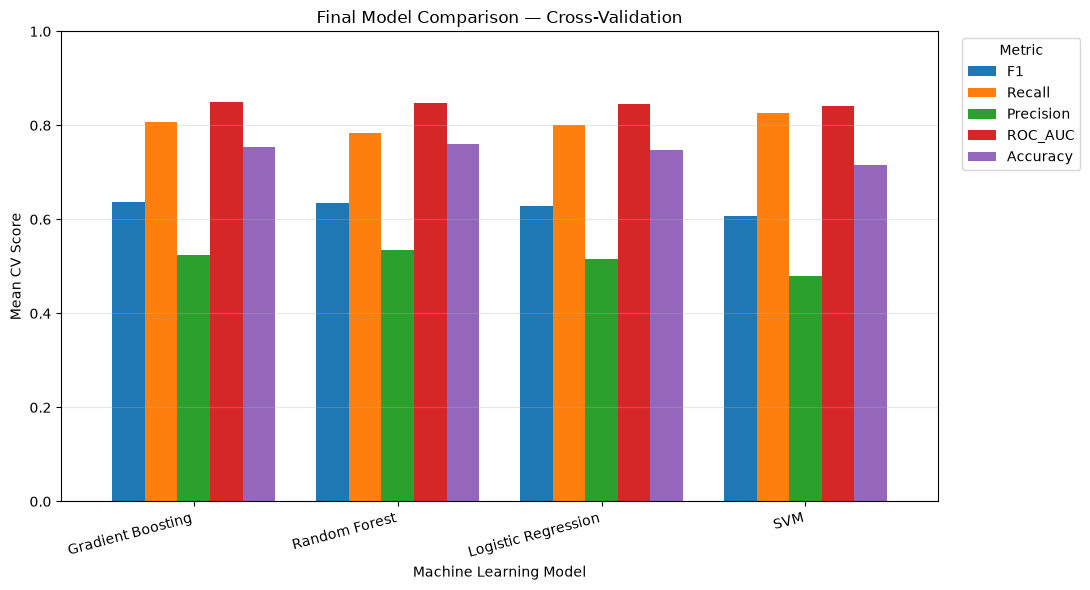

Saved: results/figures/final_comparison/final_model_comparison.png


In [11]:

metrics = [
    "F1", "Recall", "Precision",
    "ROC_AUC", "Accuracy"
]

ax = comparison_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("Final Model Comparison — Cross-Validation")
plt.xlabel("Machine Learning Model")
plt.ylabel("Mean CV Score")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "final_model_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved: results/figures/final_comparison/final_model_comparison.png")


##### Cell 7 — Select and document the winning model

In [12]:

winner = comparison_df.iloc[0]

print("Selected Model:", winner["Model"])
print("CV F1:", round(winner["F1"], 4))
print("CV Recall:", round(winner["Recall"], 4))
print("CV Precision:", round(winner["Precision"], 4))
print("CV ROC-AUC:", round(winner["ROC_AUC"], 4))

selection_df = pd.DataFrame([{
    "Selected_Model": winner["Model"],
    "Selection_Metric": "F1",
    "CV_F1": winner["F1"],
    "Reason": (
        "Highest observed cross-validation F1-score "
        "among the four candidate models."
    )
}])

selection_df.to_csv(
    tables_dir / "final_model_selection.csv",
    index=False
)

display(selection_df)

print("Saved: results/tables/final_model_selection.csv")


Selected Model: Gradient Boosting
CV F1: 0.6359
CV Recall: 0.8074
CV Precision: 0.5248
CV ROC-AUC: 0.849


,Selected_Model,Selection_Metric,CV_F1,Reason
0,Gradient Boosting,F1,0.6359,Highest observed cross-validation F1-score amo...


Saved: results/tables/final_model_selection.csv


##### Cell 8 — Load and verify the winning model

In [13]:

# Cell 8 — Load the selected Gradient Boosting model

model_path = models_dir / "gradient_boosting.joblib"

if not model_path.exists():
    raise FileNotFoundError(
        f"Model file not found: {model_path}"
    )

best_model = joblib.load(model_path)

print("Selected model: Gradient Boosting")
print("Pipeline steps:", list(best_model.named_steps.keys()))

print("\nFinal estimator:")
print(best_model.named_steps["model"])

print("\nSampler:")
print(best_model.named_steps["sampler"])


Selected model: Gradient Boosting
Pipeline steps: ['features', 'preprocessor', 'sampler', 'model']

Final estimator:
GradientBoostingClassifier(learning_rate=0.05, max_depth=2, min_samples_leaf=10,
                           n_estimators=200, random_state=42)

Sampler:
RandomOverSampler(random_state=42)


##### Cell 9 — Recreate the original train/test split

In [14]:

# Cell 9 — Load data and recreate the original split

df = load_and_clean_data(project_root)

X, y = separate_features_target(df)

X_train, X_test, y_train, y_test = (
    create_train_test_split(X, y)
)

print("Total customers:", len(df))
print("Training customers:", len(X_train))
print("Testing customers:", len(X_test))

print("\nTest class distribution:")
print(y_test.value_counts())


Total customers: 7043
Training customers: 5634
Testing customers: 1409

Test class distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


##### Cell 10 — Verify that the saved model is ready

In [15]:

# Cell 10 — Verify the saved model

from sklearn.utils.validation import check_is_fitted

check_is_fitted(best_model)

print("Saved pipeline is fitted.")

print("\nModel parameters:")
model = best_model.named_steps["model"]

print("Learning rate:", model.learning_rate)
print("Max depth:", model.max_depth)
print("Estimators:", model.n_estimators)
print("Minimum leaf samples:", model.min_samples_leaf)

print("\nReady for final test evaluation.")


Saved pipeline is fitted.

Model parameters:
Learning rate: 0.05
Max depth: 2
Estimators: 200
Minimum leaf samples: 10

Ready for final test evaluation.


##### Cell 11 — Evaluate on the held-out test set

In [16]:

# Cell 11 — Final test evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Predict test labels and probabilities
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

# Calculate metrics
test_metrics = {
    "Model": "Gradient Boosting",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1": f1_score(y_test, y_pred),
    "ROC_AUC": roc_auc_score(y_test, y_prob)
}

test_metrics_df = pd.DataFrame([test_metrics])

print("FINAL TEST METRICS")
display(test_metrics_df.round(4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred))

# Save final results
test_metrics_df.to_csv(
    tables_dir / "final_test_metrics.csv",
    index=False
)

print("\nSaved: results/tables/final_test_metrics.csv")


FINAL TEST METRICS


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Gradient Boosting,0.7459,0.5138,0.7941,0.6239,0.8447



CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1035
           1       0.51      0.79      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409


Saved: results/tables/final_test_metrics.csv


##### Cell 12 — Confusion Matrix

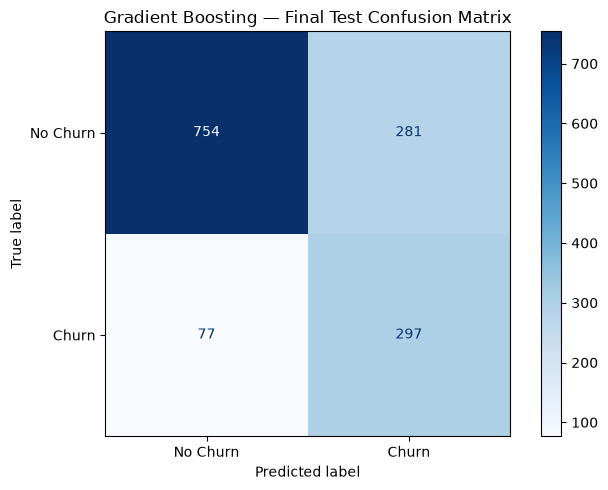

Saved final test confusion matrix.


In [17]:

# Cell 12 — Final confusion matrix

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

fig, ax = plt.subplots(figsize=(7, 5))

disp.plot(ax=ax, cmap="Blues", values_format="d")

ax.set_title("Gradient Boosting — Final Test Confusion Matrix")

plt.tight_layout()

plt.savefig(
    figures_dir / "final_test_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved final test confusion matrix.")


##### Cell 13 — ROC Curve

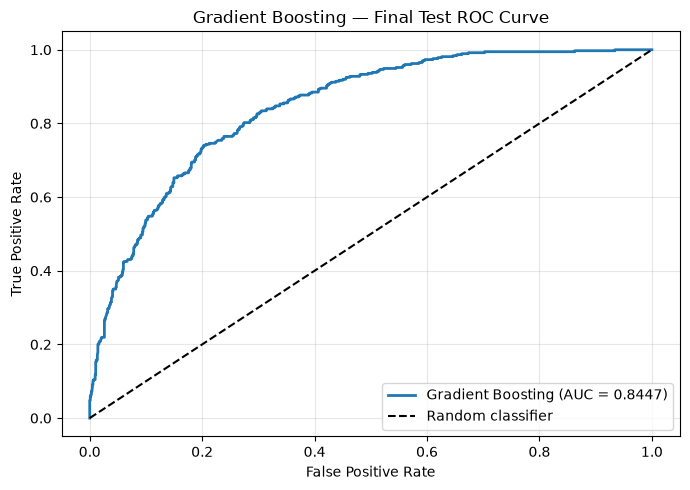

Saved final test ROC curve.


In [18]:

# Cell 13 — Final test ROC curve

from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Gradient Boosting (AUC = {auc_score:.4f})",
    linewidth=2
)

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Gradient Boosting — Final Test ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "final_test_roc_curve.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved final test ROC curve.")


##### Cell 14 — Precision-Recall Curve

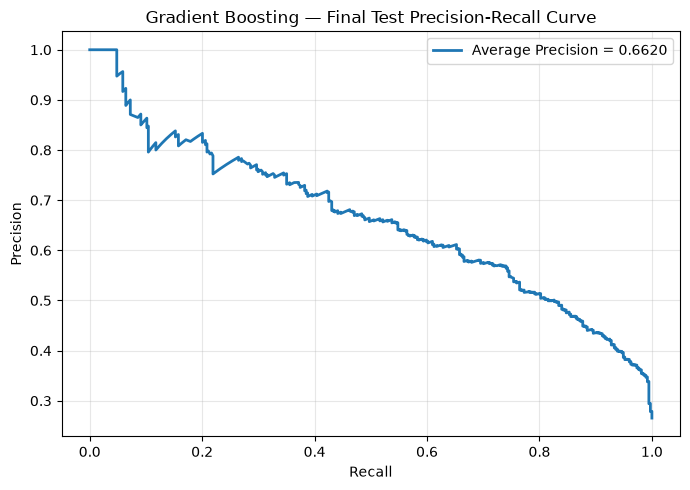

Saved final test Precision-Recall curve.


In [19]:

# Cell 14 — Final test Precision-Recall curve

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

precision, recall, thresholds = precision_recall_curve(
    y_test, y_prob
)

ap_score = average_precision_score(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    recall,
    precision,
    label=f"Average Precision = {ap_score:.4f}",
    linewidth=2
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Gradient Boosting — Final Test Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "final_test_precision_recall_curve.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved final test Precision-Recall curve.")


##### Cell 15 — Generate customer-level churn predictions

In [20]:

# Cell 15 — Generate customer churn risk scores

# Retrieve customer IDs from the original dataset
customer_ids = df.loc[X_test.index, "customerID"]

risk_df = pd.DataFrame({
    "CustomerID": customer_ids.to_numpy(),
    "Actual_Churn": y_test.to_numpy(),
    "Predicted_Churn": y_pred,
    "Churn_Probability": y_prob
})

# Sort customers from highest to lowest churn risk
risk_df = risk_df.sort_values(
    "Churn_Probability",
    ascending=False
).reset_index(drop=True)

display(risk_df.head(10))

# Save customer risk scores
risk_df.to_csv(
    tables_dir / "final_customer_churn_risk_scores.csv",
    index=False
)

print("Saved: results/tables/final_customer_churn_risk_scores.csv")


,CustomerID,Actual_Churn,Predicted_Churn,Churn_Probability
0,5178-LMXOP,1,1,0.948710
1,0295-PPHDO,1,1,0.946184
2,1069-XAIEM,1,1,0.940788
3,0970-ETWGE,1,1,0.932747
4,6230-BSUXY,1,1,0.930800
5,7181-BQYBV,1,1,0.930204
6,6023-YEBUP,1,1,0.929520
7,3722-WPXTK,1,1,0.929050
8,6861-XWTWQ,1,1,0.927274
9,8884-ADFVN,1,1,0.927274


Saved: results/tables/final_customer_churn_risk_scores.csv


##### Cell 16 — Create a high-risk customer shortlist

In [21]:

# Cell 16 — Top 100 highest-risk customers

top_100 = risk_df.head(100).copy()

top_100.insert(
    0, "Risk_Rank", range(1, len(top_100) + 1)
)

display(top_100.head(10))

top_100.to_csv(
    tables_dir / "final_top_100_high_risk_customers.csv",
    index=False
)

print("Number of customers shortlisted:", len(top_100))
print("Saved: results/tables/final_top_100_high_risk_customers.csv")


,Risk_Rank,CustomerID,Actual_Churn,Predicted_Churn,Churn_Probability
0,1,5178-LMXOP,1,1,0.948710
1,2,0295-PPHDO,1,1,0.946184
2,3,1069-XAIEM,1,1,0.940788
3,4,0970-ETWGE,1,1,0.932747
4,5,6230-BSUXY,1,1,0.930800
5,6,7181-BQYBV,1,1,0.930204
6,7,6023-YEBUP,1,1,0.929520
7,8,3722-WPXTK,1,1,0.929050
8,9,6861-XWTWQ,1,1,0.927274
9,10,8884-ADFVN,1,1,0.927274


Number of customers shortlisted: 100
Saved: results/tables/final_top_100_high_risk_customers.csv


##### Cell 17 — Evaluate the usefulness of the shortlist

In [22]:

# Cell 17 — Evaluate top-100 shortlist

top_100_actual_churners = int(
    top_100["Actual_Churn"].sum()
)

precision_at_100 = (
    top_100_actual_churners / len(top_100)
)

baseline_churn_rate = y_test.mean()

lift_at_100 = (
    precision_at_100 / baseline_churn_rate
)

shortlist_metrics = pd.DataFrame([{
    "Shortlist_Size": len(top_100),
    "Actual_Churners": top_100_actual_churners,
    "Precision_at_100": precision_at_100,
    "Baseline_Churn_Rate": baseline_churn_rate,
    "Lift_at_100": lift_at_100
}])

display(shortlist_metrics.round(4))

shortlist_metrics.to_csv(
    tables_dir / "final_shortlist_metrics.csv",
    index=False
)

print("Saved: results/tables/final_shortlist_metrics.csv")


,Shortlist_Size,Actual_Churners,Precision_at_100,Baseline_Churn_Rate,Lift_at_100
0,100,79,0.79,0.2654,2.9762


Saved: results/tables/final_shortlist_metrics.csv


##### Cell 18 — Compare high-risk customers with all test customers

In [23]:

# Cell 18 — High-risk customer profiling

profile_columns = [
    "tenure",
    "MonthlyCharges",
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity"
]

# Add risk scores to the original test features
profile_df = X_test.copy()

profile_df["Churn_Probability"] = y_prob

# Select the top 100 highest-risk customers
high_risk_profile = profile_df.nlargest(
    100, "Churn_Probability"
)

# Numerical characteristics
numerical_profile = pd.DataFrame({
    "Feature": ["tenure", "MonthlyCharges"],
    "All_Test_Customers": [
        profile_df["tenure"].mean(),
        profile_df["MonthlyCharges"].mean()
    ],
    "Top_100_High_Risk": [
        high_risk_profile["tenure"].mean(),
        high_risk_profile["MonthlyCharges"].mean()
    ]
})

display(numerical_profile.round(2))

numerical_profile.to_csv(
    tables_dir / "final_high_risk_numerical_profile.csv",
    index=False
)


,Feature,All_Test_Customers,Top_100_High_Risk
0,tenure,31.92,3.33
1,MonthlyCharges,64.09,80.98


##### Cell 19 — Categorical customer profiling

In [24]:

# Cell 19 — Categorical high-risk profiling

categorical_columns = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity"
]

categorical_results = []

for column in categorical_columns:

    all_distribution = (
        profile_df[column]
        .value_counts(normalize=True)
    )

    high_distribution = (
        high_risk_profile[column]
        .value_counts(normalize=True)
    )

    for category, proportion in high_distribution.items():

        categorical_results.append({
            "Feature": column,
            "Category": category,
            "All_Test_Percentage": (
                all_distribution.get(category, 0) * 100
            ),
            "High_Risk_Percentage": proportion * 100
        })

categorical_profile = pd.DataFrame(
    categorical_results
)

categorical_profile["Difference_Percentage_Points"] = (
    categorical_profile["High_Risk_Percentage"]
    - categorical_profile["All_Test_Percentage"]
)

categorical_profile = categorical_profile.sort_values(
    "Difference_Percentage_Points",
    ascending=False
)

display(categorical_profile.round(2))

categorical_profile.to_csv(
    tables_dir / "final_high_risk_categorical_profile.csv",
    index=False
)


,Feature,Category,All_Test_Percentage,High_Risk_Percentage,Difference_Percentage_Points
3,PaymentMethod,Electronic check,33.64,85.0,51.36
1,InternetService,Fiber optic,43.51,93.0,49.49
9,OnlineSecurity,No,49.75,99.0,49.25
7,TechSupport,No,49.82,98.0,48.18
0,Contract,Month-to-month,54.86,100.0,45.14
6,PaymentMethod,Bank transfer (automatic),21.29,5.0,-16.29
4,PaymentMethod,Credit card (automatic),21.93,5.0,-16.93
5,PaymentMethod,Mailed check,23.14,5.0,-18.14
8,TechSupport,Yes,28.03,2.0,-26.03
10,OnlineSecurity,Yes,28.11,1.0,-27.11


##### Cell 20 — Feature importance of the selected model

,Feature,Importance
37,Contract_Month-to-month,0.4179
0,tenure,0.1296
17,InternetService_Fiber optic,0.0954
19,OnlineSecurity_No,0.0794
28,TechSupport_No,0.0630
1,MonthlyCharges,0.0508
44,PaymentMethod_Electronic check,0.0491
2,TotalCharges,0.0310
39,Contract_Two year,0.0256
36,StreamingMovies_Yes,0.0123


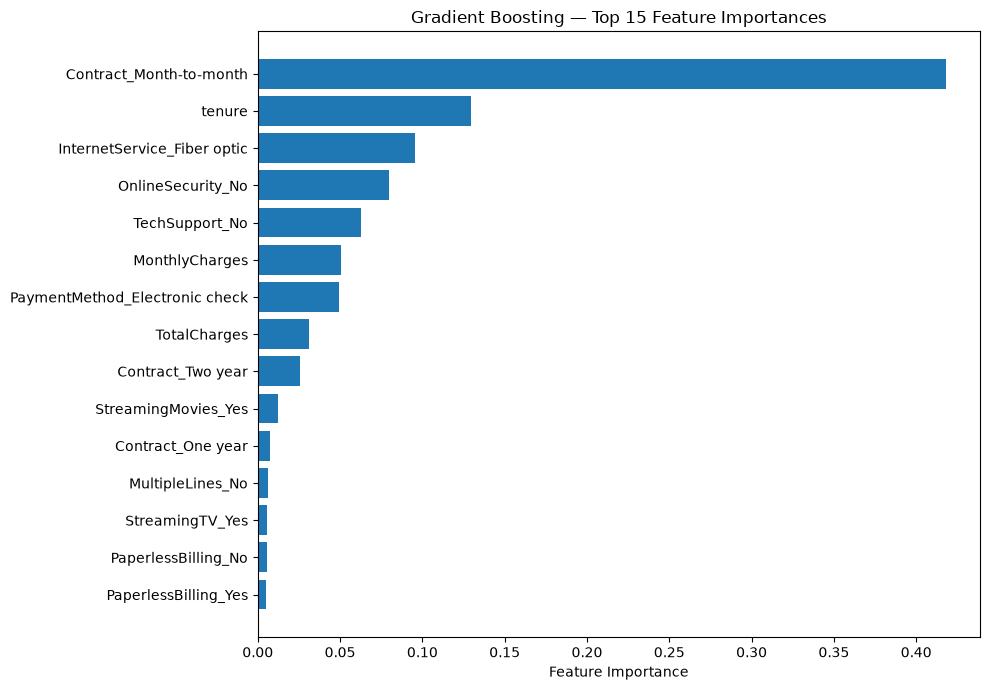

Feature importance results saved.


In [25]:

# Cell 20 — Gradient Boosting feature importance

feature_names = (
    best_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importance_values = (
    best_model.named_steps["model"]
    .feature_importances_
)

assert len(feature_names) == len(importance_values), (
    "Feature names and importance values do not match."
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
}).sort_values(
    "Importance", ascending=False
)

display(importance_df.head(15).round(4))

importance_df.to_csv(
    tables_dir / "final_feature_importance.csv",
    index=False
)

# Plot top 15 features
top_features = importance_df.head(15).iloc[::-1]

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Gradient Boosting — Top 15 Feature Importances")
plt.xlabel("Feature Importance")
plt.tight_layout()

plt.savefig(
    figures_dir / "final_feature_importance.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Feature importance results saved.")


##### Cell 21 — Save retention recommendations

In [26]:

# Cell 21 — Business retention recommendations

recommendations = pd.DataFrame([
    {
        "Finding": "Short customer tenure",
        "Evidence": "Top-100 mean tenure: 3.33 months",
        "Recommendation": "Introduce early onboarding and retention check-ins"
    },
    {
        "Finding": "Month-to-month contracts",
        "Evidence": "100% of top-100 high-risk customers",
        "Recommendation": "Test incentives for longer-term contracts"
    },
    {
        "Finding": "Higher monthly charges",
        "Evidence": "Top-100 mean: 80.98 vs 64.09 overall",
        "Recommendation": "Review pricing concerns and test targeted offers"
    },
    {
        "Finding": "No technical support",
        "Evidence": "98% of top-100 high-risk customers",
        "Recommendation": "Offer proactive technical support"
    },
    {
        "Finding": "No online security",
        "Evidence": "99% of top-100 high-risk customers",
        "Recommendation": "Promote relevant security services"
    },
    {
        "Finding": "Electronic-check payments",
        "Evidence": "85% of top-100 high-risk customers",
        "Recommendation": "Investigate payment friction and test alternatives"
    }
])

display(recommendations)

recommendations.to_csv(
    tables_dir / "final_retention_recommendations.csv",
    index=False
)

print("Saved retention recommendations.")


,Finding,Evidence,Recommendation
0,Short customer tenure,Top-100 mean tenure: 3.33 months,Introduce early onboarding and retention check...
1,Month-to-month contracts,100% of top-100 high-risk customers,Test incentives for longer-term contracts
2,Higher monthly charges,Top-100 mean: 80.98 vs 64.09 overall,Review pricing concerns and test targeted offers
3,No technical support,98% of top-100 high-risk customers,Offer proactive technical support
4,No online security,99% of top-100 high-risk customers,Promote relevant security services
5,Electronic-check payments,85% of top-100 high-risk customers,Investigate payment friction and test alternat...


Saved retention recommendations.


##### Cell 22 — Save final project summary

In [27]:

# Cell 22 — Final project summary

project_summary = pd.DataFrame([{
    "Selected_Model": "Gradient Boosting",
    "Selection_Metric": "Cross-validation F1",
    "CV_F1": 0.6359,
    "Test_F1": test_metrics_df.loc[0, "F1"],
    "Test_Recall": test_metrics_df.loc[0, "Recall"],
    "Test_Precision": test_metrics_df.loc[0, "Precision"],
    "Test_ROC_AUC": test_metrics_df.loc[0, "ROC_AUC"],
    "Test_Accuracy": test_metrics_df.loc[0, "Accuracy"],
    "Shortlist_Size": 100,
    "Actual_Churners_In_Shortlist": top_100_actual_churners,
    "Precision_At_100": precision_at_100,
    "Lift_At_100": lift_at_100
}])

display(project_summary.round(4))

project_summary.to_csv(
    tables_dir / "final_project_summary.csv",
    index=False
)

print("Saved: results/tables/final_project_summary.csv")


,Selected_Model,Selection_Metric,CV_F1,Test_F1,Test_Recall,Test_Precision,Test_ROC_AUC,Test_Accuracy,Shortlist_Size,Actual_Churners_In_Shortlist,Precision_At_100,Lift_At_100
0,Gradient Boosting,Cross-validation F1,0.6359,0.6239,0.7941,0.5138,0.8447,0.7459,100,79,0.79,2.9762


Saved: results/tables/final_project_summary.csv
